---
## Phase 2 — Spectral Signal Processing

We estimate power spectral density using Welch's method.

The investigation focuses on electrical interference
near 60 Hz at Mayo and 50 Hz at FNUSA.

Initial experiments examine representative recordings
before expanding to recordings from different participants.

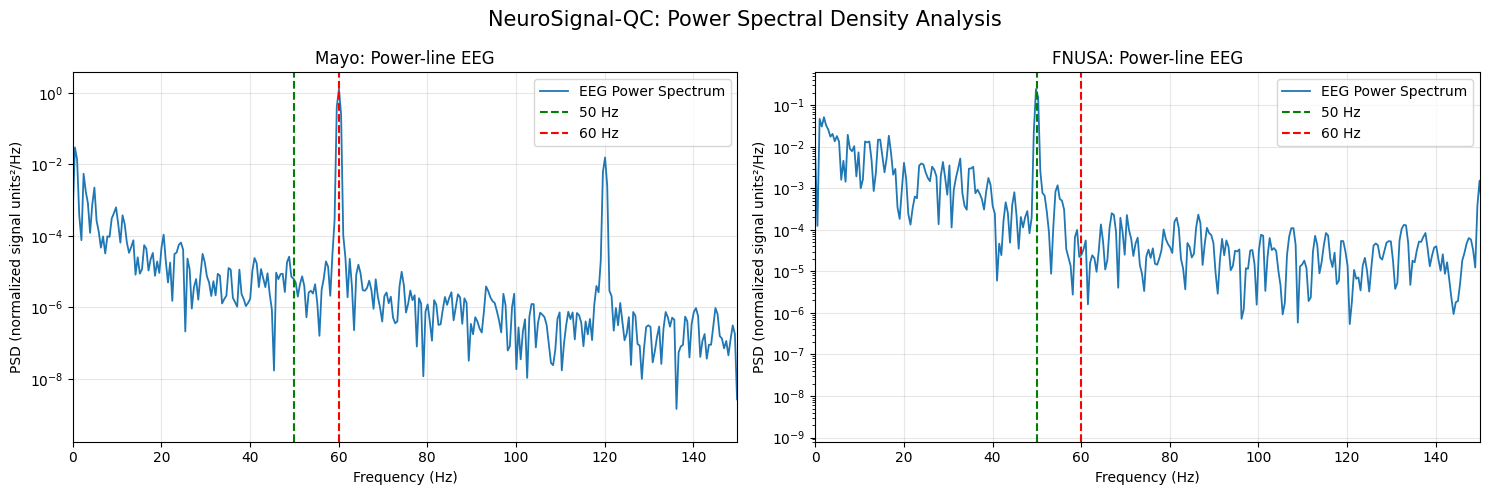

POWER SPECTRAL DENSITY RESULTS


,Hospital,Expected Mains Frequency,Dominant Frequency (Hz),Relative Power 50 Hz,Relative Power 60 Hz
0,Mayo,60,60.05859,0.00003,0.97953
1,FNUSA,50,49.80469,0.46567,0.00033


In [8]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 1
# Power Spectral Density: Electrical Interference
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch

# ------------------------------------------------------------
# 1. Select power-line recordings
# ------------------------------------------------------------

hospitals = ["Mayo", "FNUSA"]

psd_results = []

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# ------------------------------------------------------------
# 2. Calculate Welch Power Spectral Density
# ------------------------------------------------------------

for i, hospital in enumerate(hospitals):

    data = waveforms[(hospital, "Power-line")]

    signal = data["signal"]
    fs = data["sampling_rate"]

    # Welch PSD estimation
    frequencies, psd = welch(
        signal,
        fs=fs,
        window="hann",
        nperseg=2048,
        noverlap=1024,
        detrend="constant",
        scaling="density"
    )

    # --------------------------------------------------------
    # 3. Identify dominant frequency between 40 and 70 Hz
    # --------------------------------------------------------

    search_mask = (
        (frequencies >= 40)
        & (frequencies <= 70)
    )

    search_frequencies = frequencies[search_mask]
    search_psd = psd[search_mask]

    dominant_frequency = search_frequencies[
        np.argmax(search_psd)
    ]

    # --------------------------------------------------------
    # 4. Calculate relative spectral power
    # --------------------------------------------------------

    total_mask = (
        (frequencies >= 1)
        & (frequencies <= 150)
    )

    power_50_mask = (
        (frequencies >= 48)
        & (frequencies <= 52)
    )

    power_60_mask = (
        (frequencies >= 58)
        & (frequencies <= 62)
    )

    total_power = np.trapezoid(
        psd[total_mask],
        frequencies[total_mask]
    )

    power_50 = np.trapezoid(
        psd[power_50_mask],
        frequencies[power_50_mask]
    )

    power_60 = np.trapezoid(
        psd[power_60_mask],
        frequencies[power_60_mask]
    )

    relative_50 = (
        power_50 / total_power
        if total_power > 0 else np.nan
    )

    relative_60 = (
        power_60 / total_power
        if total_power > 0 else np.nan
    )

    psd_results.append({
        "Hospital": hospital,
        "Expected Mains Frequency": (
            60 if hospital == "Mayo" else 50
        ),
        "Dominant Frequency (Hz)": dominant_frequency,
        "Relative Power 50 Hz": relative_50,
        "Relative Power 60 Hz": relative_60
    })

    # --------------------------------------------------------
    # 5. Visualize PSD
    # --------------------------------------------------------

    ax = axes[i]

    ax.semilogy(
        frequencies,
        psd,
        linewidth=1.3,
        label="EEG Power Spectrum"
    )

    ax.axvline(
        50,
        color="green",
        linestyle="--",
        label="50 Hz"
    )

    ax.axvline(
        60,
        color="red",
        linestyle="--",
        label="60 Hz"
    )

    ax.set_xlim(0, 150)

    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel(
        "PSD (normalized signal units²/Hz)"
    )

    ax.set_title(
        f"{hospital}: Power-line EEG"
    )

    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "NeuroSignal-QC: Power Spectral Density Analysis",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

psd_df = pd.DataFrame(psd_results)

print("=" * 65)
print("POWER SPECTRAL DENSITY RESULTS")
print("=" * 65)

display(psd_df.round(5))

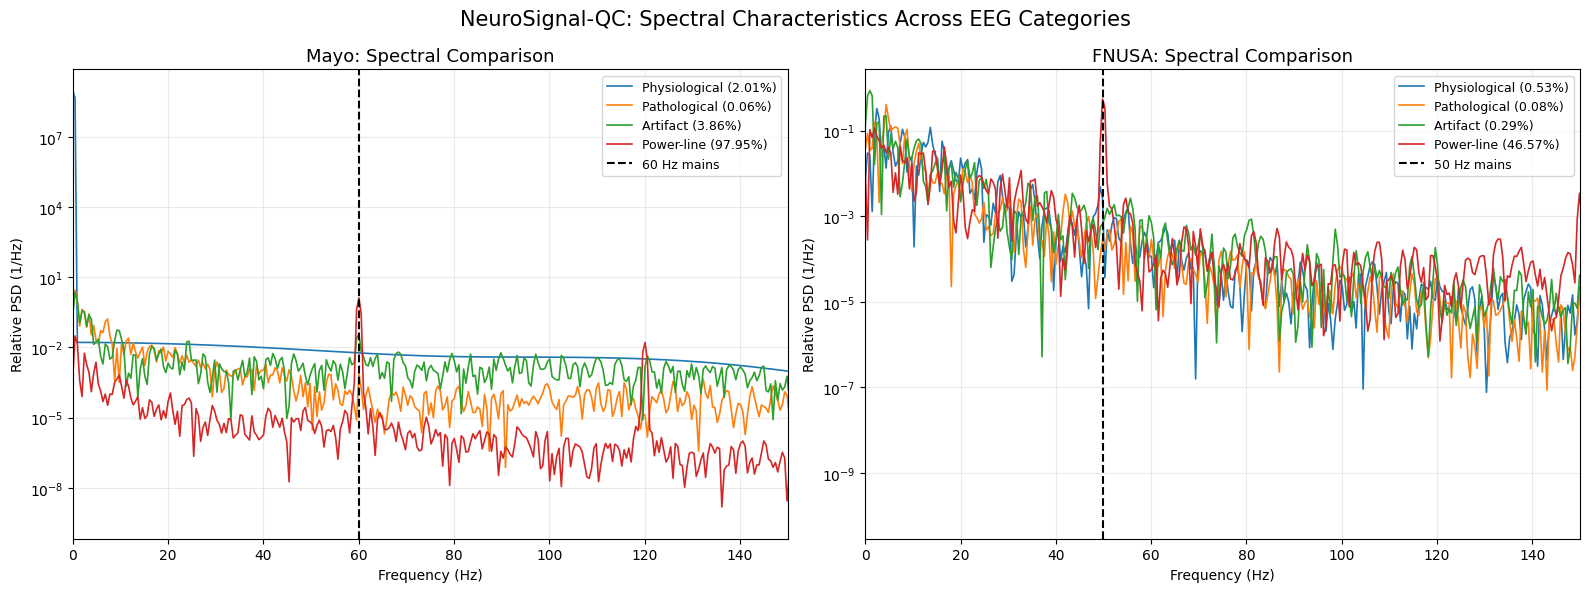

SPECTRAL POWER COMPARISON


,Hospital,Category,Mains Frequency (Hz),Mains Power (%),Total Power (1-150 Hz)
0,Mayo,Physiological,60,2.0076,0.0000
1,Mayo,Pathological,60,0.0590,0.1330
2,Mayo,Artifact,60,3.8574,0.0226
3,Mayo,Power-line,60,97.9528,0.9584
4,FNUSA,Physiological,50,0.5333,0.8782
5,FNUSA,Pathological,50,0.0768,1.5562
6,FNUSA,Artifact,50,0.2890,0.2474
7,FNUSA,Power-line,50,46.5668,0.4473



MAINS-FREQUENCY POWER BY CATEGORY (%)


Hospital,FNUSA,Mayo
Category,,
Physiological,0.533,2.008
Pathological,0.077,0.059
Artifact,0.289,3.857
Power-line,46.567,97.953



Spectral comparison complete.


In [9]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 2
# Spectral Comparison Across EEG Categories
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

MAINS_FREQUENCIES = {
    "Mayo": 60,
    "FNUSA": 50
}

spectral_records = []

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

# ------------------------------------------------------------
# Analyze each hospital
# ------------------------------------------------------------

for i, hospital in enumerate(["Mayo", "FNUSA"]):

    ax = axes[i]

    mains_frequency = MAINS_FREQUENCIES[hospital]

    for category in CATEGORIES:

        data = waveforms[(hospital, category)]

        eeg = np.asarray(
            data["signal"],
            dtype=np.float64
        )

        fs = float(data["sampling_rate"])

        # ----------------------------------------------------
        # Calculate Power Spectral Density
        # ----------------------------------------------------

        frequencies, psd = welch(
            eeg,
            fs=fs,
            window="hann",
            nperseg=2048,
            noverlap=1024,
            detrend="constant",
            scaling="density"
        )

        # ----------------------------------------------------
        # Calculate total spectral power (1–150 Hz)
        # ----------------------------------------------------

        total_mask = (
            (frequencies >= 1)
            & (frequencies <= 150)
        )

        total_power = np.trapezoid(
            psd[total_mask],
            frequencies[total_mask]
        )

        # ----------------------------------------------------
        # Calculate mains-frequency power (±2 Hz)
        # ----------------------------------------------------

        mains_mask = (
            (frequencies >= mains_frequency - 2)
            & (frequencies <= mains_frequency + 2)
        )

        mains_power = np.trapezoid(
            psd[mains_mask],
            frequencies[mains_mask]
        )

        relative_mains_power = (
            mains_power / total_power
            if total_power > 0
            else np.nan
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        spectral_records.append({
            "Hospital": hospital,
            "Category": category,
            "Mains Frequency (Hz)": mains_frequency,
            "Mains Power (%)": relative_mains_power * 100,
            "Total Power (1-150 Hz)": total_power
        })

        # ----------------------------------------------------
        # Normalize PSD for shape comparison
        # ----------------------------------------------------

        normalized_psd = (
            psd / total_power
            if total_power > 0
            else np.full_like(psd, np.nan)
        )

        ax.semilogy(
            frequencies,
            normalized_psd,
            linewidth=1.2,
            label=(
                f"{category} "
                f"({relative_mains_power * 100:.2f}%)"
            )
        )

    # --------------------------------------------------------
    # Plot hospital-specific mains frequency
    # --------------------------------------------------------

    ax.axvline(
        mains_frequency,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"{mains_frequency} Hz mains"
    )

    ax.set_xlim(0, 150)

    ax.set_xlabel("Frequency (Hz)")

    ax.set_ylabel(
        "Relative PSD (1/Hz)"
    )

    ax.set_title(
        f"{hospital}: Spectral Comparison",
        fontsize=13
    )

    ax.legend(fontsize=9)

    ax.grid(alpha=0.25)

plt.suptitle(
    "NeuroSignal-QC: Spectral Characteristics Across EEG Categories",
    fontsize=15
)

plt.tight_layout()

plt.show()

# ============================================================
# RESULTS TABLE
# ============================================================

spectral_comparison_df = pd.DataFrame(
    spectral_records
)

print("=" * 70)
print("SPECTRAL POWER COMPARISON")
print("=" * 70)

display(
    spectral_comparison_df.round(4)
)

# ------------------------------------------------------------
# Compare mains power across categories
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MAINS-FREQUENCY POWER BY CATEGORY (%)")
print("=" * 70)

comparison_table = spectral_comparison_df.pivot(
    index="Category",
    columns="Hospital",
    values="Mains Power (%)"
)

display(
    comparison_table.reindex(CATEGORIES).round(3)
)

print("\nSpectral comparison complete.")

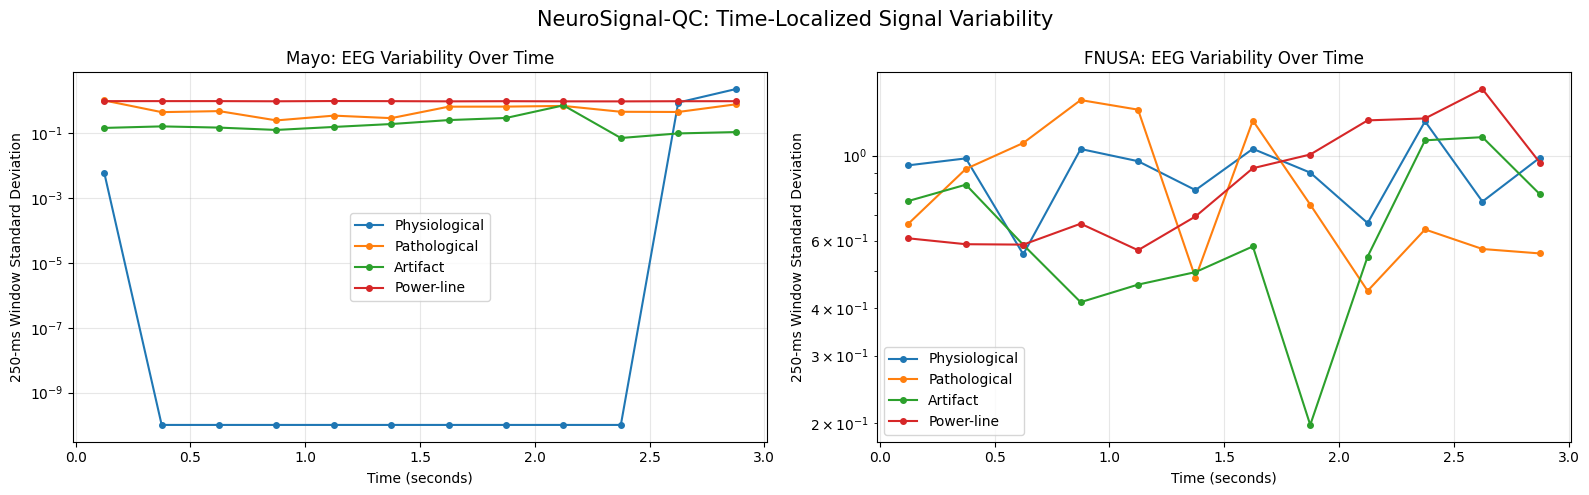

TIME-LOCALIZED EEG VARIABILITY RESULTS


,Hospital,Category,Full Signal Std,First 2s Std,Last 0.5s Std,Min Window Std,Max Window Std,Max/Min Variability Ratio
0,Mayo,Physiological,0.996930,0.002137,2.085188,0.000000,2.329077,8.391385e+16
1,Mayo,Pathological,0.998521,1.044461,0.769840,0.252071,1.040723,4.128696e+00
2,Mayo,Artifact,0.999837,0.486367,0.158647,0.072161,0.734323,1.017624e+01
3,Mayo,Power-line,1.000474,1.003892,0.986534,0.974044,0.998248,1.024849e+00
4,FNUSA,Physiological,1.000172,0.982754,0.976329,0.552245,1.229493,2.226354e+00
5,FNUSA,Pathological,1.000006,1.109743,0.598679,0.443085,1.397247,3.153448e+00
6,FNUSA,Artifact,1.000044,0.776288,1.069974,0.197747,1.117668,5.652011e+00
7,FNUSA,Power-line,1.000252,0.808702,1.277107,0.566043,1.492384,2.636520e+00



MAYO PHYSIOLOGICAL RECORDING — FOCUSED AUDIT


,0
Hospital,Mayo
Category,Physiological
Full Signal Std,0.99693
First 2s Std,0.002137
Last 0.5s Std,2.085188
Min Window Std,0.0
Max Window Std,2.329077
Max/Min Variability Ratio,83913854523527232.0



Time-localized variability analysis complete.


In [10]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 3
# Time-Localized EEG Variability Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

HOSPITALS = ["Mayo", "FNUSA"]

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

WINDOW_DURATION = 0.25  # 250 milliseconds

variability_records = []

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5)
)

# ------------------------------------------------------------
# Analyze each recording
# ------------------------------------------------------------

for i, hospital in enumerate(HOSPITALS):

    ax = axes[i]

    for category in CATEGORIES:

        data = waveforms[(hospital, category)]

        eeg = np.asarray(
            data["signal"],
            dtype=np.float64
        )

        fs = float(data["sampling_rate"])

        # ----------------------------------------------------
        # Divide EEG into non-overlapping 250-ms windows
        # ----------------------------------------------------

        window_samples = int(
            round(WINDOW_DURATION * fs)
        )

        n_windows = len(eeg) // window_samples

        trimmed_eeg = eeg[
            :n_windows * window_samples
        ]

        windows = trimmed_eeg.reshape(
            n_windows,
            window_samples
        )

        # ----------------------------------------------------
        # Calculate standard deviation in each window
        # ----------------------------------------------------

        window_std = np.std(
            windows,
            axis=1
        )

        window_times = (
            np.arange(n_windows) + 0.5
        ) * WINDOW_DURATION

        # ----------------------------------------------------
        # Compare early and late recording variability
        # ----------------------------------------------------

        first_2s = eeg[
            :int(2 * fs)
        ]

        last_05s = eeg[
            -int(0.5 * fs):
        ]

        first_2s_std = np.std(first_2s)

        last_05s_std = np.std(last_05s)

        min_window_std = np.min(window_std)

        max_window_std = np.max(window_std)

        variability_ratio = (
            max_window_std / min_window_std
            if min_window_std > 0
            else np.inf
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        variability_records.append({
            "Hospital": hospital,
            "Category": category,
            "Full Signal Std": np.std(eeg),
            "First 2s Std": first_2s_std,
            "Last 0.5s Std": last_05s_std,
            "Min Window Std": min_window_std,
            "Max Window Std": max_window_std,
            "Max/Min Variability Ratio": variability_ratio
        })

        # ----------------------------------------------------
        # Plot time-localized variability
        # ----------------------------------------------------

        ax.plot(
            window_times,
            np.maximum(window_std, 1e-10),
            marker="o",
            markersize=4,
            linewidth=1.5,
            label=category
        )

    ax.set_title(
        f"{hospital}: EEG Variability Over Time"
    )

    ax.set_xlabel(
        "Time (seconds)"
    )

    ax.set_ylabel(
        "250-ms Window Standard Deviation"
    )

    ax.set_yscale("log")

    ax.grid(
        alpha=0.3
    )

    ax.legend()

plt.suptitle(
    "NeuroSignal-QC: Time-Localized Signal Variability",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ============================================================
# RESULTS
# ============================================================

variability_df = pd.DataFrame(
    variability_records
)

print("=" * 70)
print("TIME-LOCALIZED EEG VARIABILITY RESULTS")
print("=" * 70)

display(
    variability_df.round(6)
)

# ------------------------------------------------------------
# Highlight the suspicious Mayo physiological recording
# ------------------------------------------------------------

mayo_physiological = variability_df[
    (variability_df["Hospital"] == "Mayo")
    &
    (variability_df["Category"] == "Physiological")
]

print("\n" + "=" * 70)
print("MAYO PHYSIOLOGICAL RECORDING — FOCUSED AUDIT")
print("=" * 70)

display(
    mayo_physiological.T
)

print("\nTime-localized variability analysis complete.")

EEG FLATLINE AND SIGNAL INTEGRITY AUDIT


,Hospital,Category,Longest Constant Run (samples),Longest Constant Run (s),Identical Adjacent Samples (%),Unique Signal Values
0,Mayo,Physiological,2616,2.616,88.69623,307
1,Mayo,Pathological,1,0.001,0.00000,2842
2,Mayo,Artifact,2,0.002,0.16672,2720
3,Mayo,Power-line,1,0.001,0.00000,2790
4,FNUSA,Physiological,2,0.002,0.06669,2770
5,FNUSA,Pathological,2,0.002,0.23341,2653
6,FNUSA,Artifact,2,0.002,0.10003,2809
7,FNUSA,Power-line,2,0.002,0.03334,2792


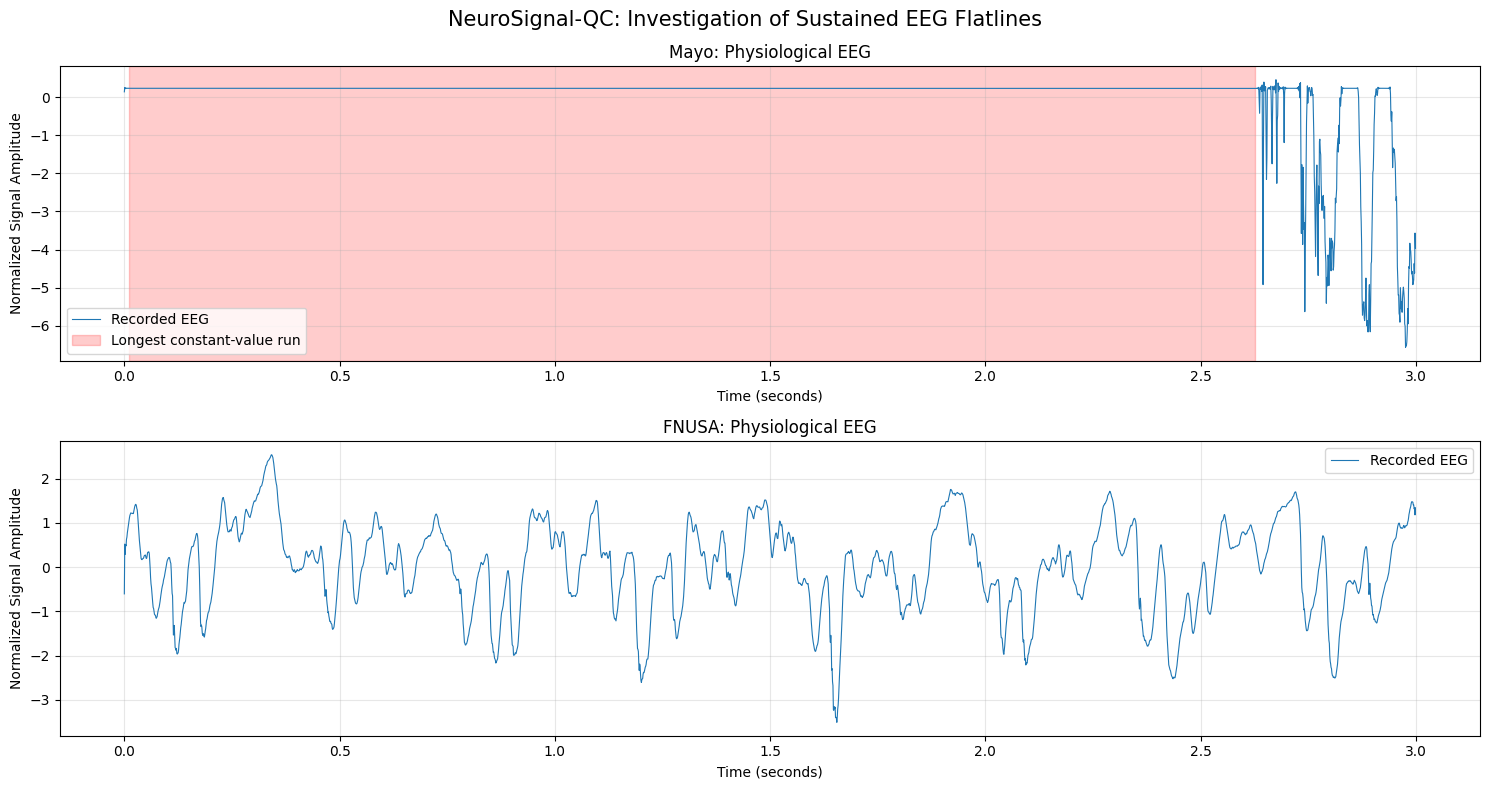


MAYO PHYSIOLOGICAL EEG — FLATLINE DETAILS
Longest constant-value run starts at: 0.0100 seconds
Longest constant-value run ends at: 2.6260 seconds
Duration: 2.6160 seconds

Flatline investigation complete.


In [11]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 4
# Sustained Flatline and Signal Integrity Audit
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Detect consecutive identical signal values
# ------------------------------------------------------------

flatline_records = []
flatline_locations = {}

for (hospital, category), data in waveforms.items():

    eeg = np.asarray(
        data["signal"],
        dtype=np.float64
    )

    fs = float(data["sampling_rate"])

    # Identify where signal values change
    changes = np.flatnonzero(
        np.r_[True, eeg[1:] != eeg[:-1]]
    )

    # Determine start and end of each constant-value run
    run_starts = changes

    run_ends = np.r_[
        changes[1:],
        len(eeg)
    ]

    run_lengths = run_ends - run_starts

    # Find longest constant-value sequence
    longest_idx = np.argmax(run_lengths)

    longest_start = int(run_starts[longest_idx])
    longest_end = int(run_ends[longest_idx])

    longest_samples = int(
        run_lengths[longest_idx]
    )

    longest_duration = longest_samples / fs

    # Percentage of adjacent samples with identical values
    identical_fraction = (
        np.mean(np.diff(eeg) == 0) * 100
    )

    # Number of distinct amplitude values
    unique_values = len(np.unique(eeg))

    flatline_records.append({
        "Hospital": hospital,
        "Category": category,
        "Longest Constant Run (samples)": longest_samples,
        "Longest Constant Run (s)": longest_duration,
        "Identical Adjacent Samples (%)": identical_fraction,
        "Unique Signal Values": unique_values
    })

    flatline_locations[(hospital, category)] = {
        "start": longest_start / fs,
        "end": longest_end / fs,
        "duration": longest_duration
    }

# ------------------------------------------------------------
# 2. Display signal-integrity summary
# ------------------------------------------------------------

flatline_df = pd.DataFrame(flatline_records)

print("=" * 70)
print("EEG FLATLINE AND SIGNAL INTEGRITY AUDIT")
print("=" * 70)

display(flatline_df.round(5))

# ------------------------------------------------------------
# 3. Compare physiological recordings visually
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 8)
)

for i, hospital in enumerate(["Mayo", "FNUSA"]):

    category = "Physiological"

    data = waveforms[(hospital, category)]

    eeg = data["signal"]
    time = data["time"]

    location = flatline_locations[
        (hospital, category)
    ]

    ax = axes[i]

    ax.plot(
        time,
        eeg,
        linewidth=0.8,
        label="Recorded EEG"
    )

    # Highlight sustained constant-value periods
    if location["duration"] >= 0.1:

        ax.axvspan(
            location["start"],
            location["end"],
            color="red",
            alpha=0.2,
            label="Longest constant-value run"
        )

    ax.set_title(
        f"{hospital}: Physiological EEG"
    )

    ax.set_xlabel("Time (seconds)")

    ax.set_ylabel(
        "Normalized Signal Amplitude"
    )

    ax.legend()

    ax.grid(alpha=0.3)

plt.suptitle(
    "NeuroSignal-QC: Investigation of Sustained EEG Flatlines",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Focused Mayo investigation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MAYO PHYSIOLOGICAL EEG — FLATLINE DETAILS")
print("=" * 70)

mayo_location = flatline_locations[
    ("Mayo", "Physiological")
]

print(
    f"Longest constant-value run starts at: "
    f"{mayo_location['start']:.4f} seconds"
)

print(
    f"Longest constant-value run ends at: "
    f"{mayo_location['end']:.4f} seconds"
)

print(
    f"Duration: "
    f"{mayo_location['duration']:.4f} seconds"
)

print("\nFlatline investigation complete.")

NEIGHBORING EEG SEGMENT INVESTIGATION

Hospital: Mayo
Subject: 000
Recording: sub-000/ieeg/sub-000_task-MachineLearningEEG_run-004_ieeg.zarr
Target sample index: 0
Neighboring events selected: 3

NEIGHBORING SEGMENT QUALITY COMPARISON


,Sample Index,Start Time (s),Annotation,Target Segment,Signal Std,Longest Flatline (s),Identical Samples (%)
0,0,0.0,physiology,True,0.99693,2.616,88.69623
1,3000,3.0,noise,False,0.99967,0.002,0.06669
2,6000,6.0,noise,False,0.99974,0.002,0.10003


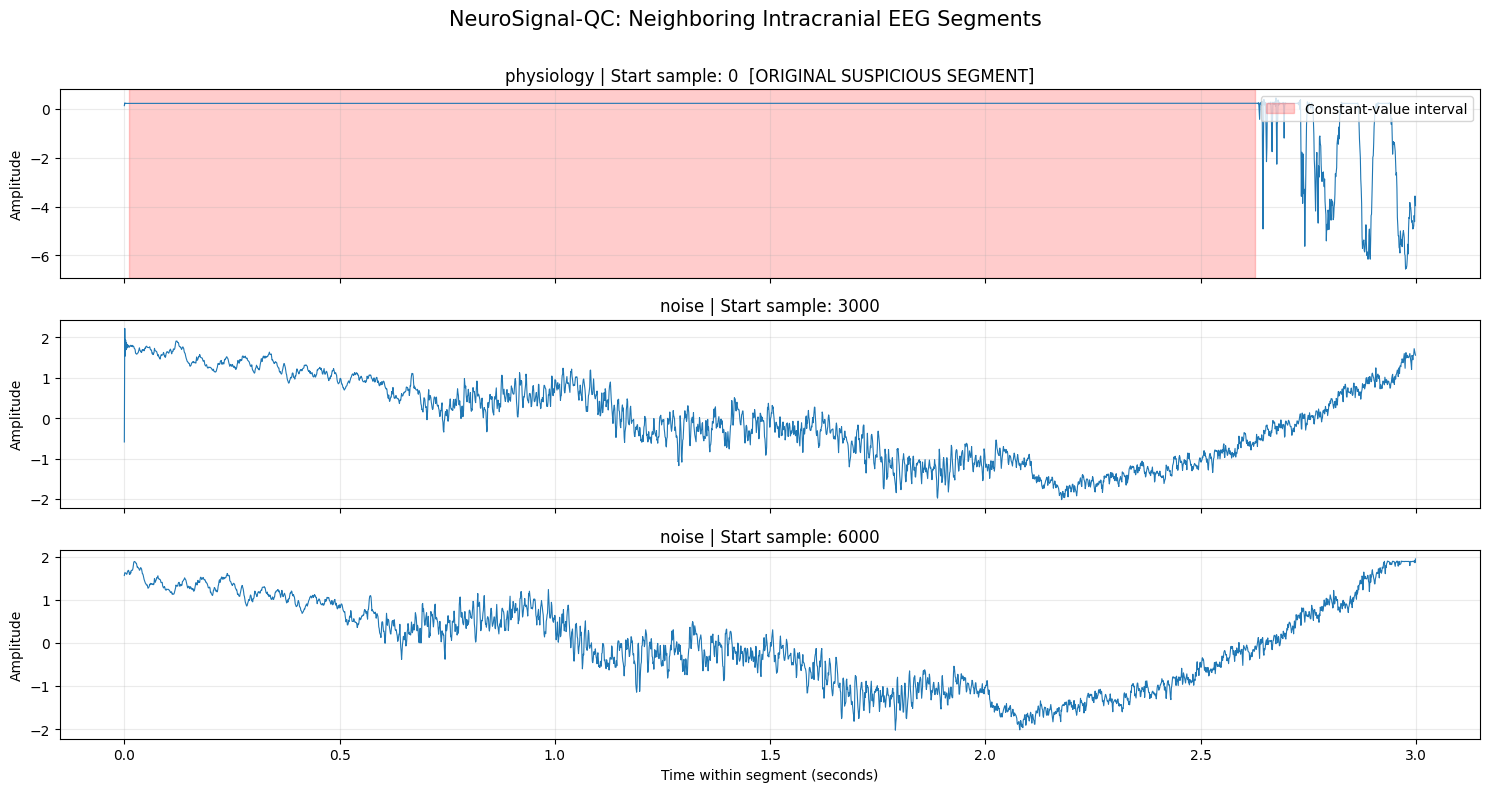


Neighboring segment investigation complete.


In [12]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 5
# Investigating Neighboring EEG Segments
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zarr

from zarr.storage import FsspecStore

# ------------------------------------------------------------
# 1. Identify the suspicious Mayo physiological segment
# ------------------------------------------------------------

target = next(
    clip for clip in selected_clips
    if clip["hospital"] == "Mayo"
    and clip["category"] == "Physiological"
)

store_path = target["store"]["zarr"]
group_name = target["group"]["name"]
target_start = int(target["start_sample"])

# Retrieve annotations from the same recording
recording_events = events["Mayo"][
    (events["Mayo"]["store_path"] == store_path)
    &
    (events["Mayo"]["group_name"] == group_name)
].copy()

recording_events = (
    recording_events
    .sort_values("sample_index")
    .reset_index(drop=True)
)

# Locate the selected event
matches = np.flatnonzero(
    recording_events["sample_index"].to_numpy()
    == target_start
)

if len(matches) == 0:
    raise ValueError("Selected EEG segment not found.")

target_position = int(matches[0])

# Select up to two preceding and two following events
start_position = max(0, target_position - 2)
end_position = min(
    len(recording_events),
    target_position + 3
)

neighbor_events = recording_events.iloc[
    start_position:end_position
].copy()

print("=" * 70)
print("NEIGHBORING EEG SEGMENT INVESTIGATION")
print("=" * 70)

print(f"\nHospital: Mayo")
print(f"Subject: {target['subject']}")
print(f"Recording: {store_path}")
print(f"Target sample index: {target_start}")
print(f"Neighboring events selected: {len(neighbor_events)}")

# ------------------------------------------------------------
# 2. Load the EEG recording
# ------------------------------------------------------------

s3_uri = (
    f"s3://nemar/nm000182/zarr/{store_path}"
)

remote_store = FsspecStore.from_url(
    s3_uri,
    storage_options={
        "anon": True,
        "client_kwargs": {
            "region_name": "us-east-2"
        }
    }
)

root = zarr.open_group(
    store=remote_store,
    mode="r",
    zarr_format=3
)

group = root[group_name]
signal_array = group["0"]

fs = float(group.attrs["rate"])

scale = float(signal_array.attrs["scale"][0])
offset = float(signal_array.attrs["offset"][0])

# ------------------------------------------------------------
# 3. Analyze neighboring EEG segments
# ------------------------------------------------------------

neighbor_results = []
neighbor_signals = []

for _, row in neighbor_events.iterrows():

    segment_start = int(row["sample_index"])

    duration = float(row["duration_s"])

    n_samples = int(round(duration * fs))

    digital = np.asarray(
        signal_array[
            0,
            segment_start:segment_start + n_samples
        ],
        dtype=np.float64
    )

    eeg = digital * scale + offset

    if len(eeg) != n_samples:
        raise ValueError(
            f"Incomplete segment at sample {segment_start}"
        )

    # Detect consecutive identical values
    change_points = np.flatnonzero(
        np.r_[True, eeg[1:] != eeg[:-1]]
    )

    run_starts = change_points

    run_ends = np.r_[
        change_points[1:],
        len(eeg)
    ]

    run_lengths = run_ends - run_starts

    longest_idx = int(np.argmax(run_lengths))

    longest_start = int(run_starts[longest_idx])
    longest_end = int(run_ends[longest_idx])

    longest_duration = (
        run_lengths[longest_idx] / fs
    )

    identical_percentage = (
        np.mean(np.diff(eeg) == 0) * 100
    )

    is_target = (
        segment_start == target_start
    )

    neighbor_results.append({
        "Sample Index": segment_start,
        "Start Time (s)": segment_start / fs,
        "Annotation": row["trial_type"],
        "Target Segment": is_target,
        "Signal Std": np.std(eeg),
        "Longest Flatline (s)": longest_duration,
        "Identical Samples (%)": identical_percentage
    })

    neighbor_signals.append({
        "signal": eeg,
        "annotation": row["trial_type"],
        "sample_index": segment_start,
        "is_target": is_target,
        "flatline_start": longest_start / fs,
        "flatline_end": longest_end / fs,
        "flatline_duration": longest_duration
    })

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

neighbor_df = pd.DataFrame(neighbor_results)

print("\n" + "=" * 70)
print("NEIGHBORING SEGMENT QUALITY COMPARISON")
print("=" * 70)

display(neighbor_df.round(5))

# ------------------------------------------------------------
# 5. Visualize neighboring recordings
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(neighbor_signals),
    1,
    figsize=(15, 2.6 * len(neighbor_signals)),
    sharex=True
)

axes = np.atleast_1d(axes)

for ax, data in zip(axes, neighbor_signals):

    eeg = data["signal"]

    time = np.arange(len(eeg)) / fs

    ax.plot(
        time,
        eeg,
        linewidth=0.8
    )

    # Highlight constant-value intervals
    if data["flatline_duration"] >= 0.1:

        ax.axvspan(
            data["flatline_start"],
            data["flatline_end"],
            color="red",
            alpha=0.2,
            label="Constant-value interval"
        )

        ax.legend(loc="upper right")

    title = (
        f"{data['annotation']} | "
        f"Start sample: {data['sample_index']}"
    )

    if data["is_target"]:
        title += "  [ORIGINAL SUSPICIOUS SEGMENT]"

    ax.set_title(title)

    ax.set_ylabel("Amplitude")

    ax.grid(alpha=0.25)

axes[-1].set_xlabel(
    "Time within segment (seconds)"
)

plt.suptitle(
    "NeuroSignal-QC: Neighboring Intracranial EEG Segments",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

print("\nNeighboring segment investigation complete.")

### Patient-Diverse Signal Integrity Assessment

An initial physiological-labeled recording contained
a prolonged constant-value interval.

We investigate whether similar intervals occur in
a small, reproducibly selected participant-diverse sample.

The exploratory flatline threshold is not
a validated clinical signal-quality criterion.

In [14]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 6 (CORRECTED)
# Patient-Diverse EEG Signal Integrity Audit
# ============================================================

import numpy as np
import pandas as pd
import zarr

from zarr.storage import FsspecStore
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

HOSPITALS = ["Mayo", "FNUSA"]

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

SUBJECTS_PER_CATEGORY = 6

RANDOM_SEED = 42

# Exploratory flatline threshold (NOT a clinical cutoff)
FLATLINE_THRESHOLD_SECONDS = 0.1

audit_results = []

# Cache opened recording stores
opened_stores = {}

print("=" * 70)
print("NEUROSIGNAL-QC — PATIENT-DIVERSE SIGNAL INTEGRITY AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 2. Select clips from different participants
# ------------------------------------------------------------

for hospital in HOSPITALS:

    dataset_id = DATASETS[hospital]

    hospital_events = events[hospital]

    print(f"\nAnalyzing hospital: {hospital}")

    for category in CATEGORIES:

        category_events = hospital_events[
            hospital_events["label"] == category
        ].copy()

        category_events = category_events.dropna(
            subset=["sample_index", "subject"]
        )

        category_events = category_events[
            category_events["sample_index"] >= 0
        ]

        # Randomly select one clip per participant
        # FIX: observed=True ignores empty categorical groups
        one_per_subject = (
            category_events
            .groupby(
                "subject",
                group_keys=False,
                observed=True
            )
            .sample(
                n=1,
                random_state=RANDOM_SEED
            )
        )

        # Select up to six distinct participants
        n_select = min(
            SUBJECTS_PER_CATEGORY,
            len(one_per_subject)
        )

        selected = one_per_subject.sample(
            n=n_select,
            random_state=RANDOM_SEED
        )

        print(
            f"  {category}: "
            f"{len(selected)} clips selected"
        )

        # ----------------------------------------------------
        # 3. Retrieve each EEG clip
        # ----------------------------------------------------

        for _, row in selected.iterrows():

            store_path = row["store_path"]
            group_name = row["group_name"]

            cache_key = (
                dataset_id,
                store_path
            )

            # Avoid reopening the same remote recording
            if cache_key not in opened_stores:

                s3_uri = (
                    f"s3://nemar/{dataset_id}/zarr/"
                    f"{store_path}"
                )

                remote_store = FsspecStore.from_url(
                    s3_uri,
                    storage_options={
                        "anon": True,
                        "client_kwargs": {
                            "region_name": "us-east-2"
                        }
                    }
                )

                opened_stores[cache_key] = (
                    zarr.open_group(
                        store=remote_store,
                        mode="r",
                        zarr_format=3
                    )
                )

            root = opened_stores[cache_key]

            group = root[group_name]

            signal_array = group["0"]

            fs = float(group.attrs["rate"])

            start = int(row["sample_index"])

            n_samples = int(
                round(float(row["duration_s"]) * fs)
            )

            # Read EEG samples
            digital = np.asarray(
                signal_array[
                    0,
                    start:start + n_samples
                ],
                dtype=np.float64
            )

            if len(digital) != n_samples:
                raise ValueError(
                    f"Incomplete EEG clip: "
                    f"{hospital}, {row['subject']}"
                )

            # Convert using stored scale and offset
            scale = float(
                signal_array.attrs["scale"][0]
            )

            offset = float(
                signal_array.attrs["offset"][0]
            )

            eeg = digital * scale + offset

            if not np.all(np.isfinite(eeg)):
                raise ValueError(
                    f"Nonfinite values in "
                    f"{hospital}, {row['subject']}"
                )

            # ------------------------------------------------
            # 4. Detect constant-value intervals
            # ------------------------------------------------

            changes = np.flatnonzero(
                np.r_[
                    True,
                    eeg[1:] != eeg[:-1]
                ]
            )

            run_starts = changes

            run_ends = np.r_[
                changes[1:],
                len(eeg)
            ]

            run_lengths = run_ends - run_starts

            longest_run_samples = int(
                np.max(run_lengths)
            )

            longest_flatline = (
                longest_run_samples / fs
            )

            identical_percentage = (
                np.mean(np.diff(eeg) == 0) * 100
            )

            # Exploratory flag
            flatline_flag = (
                longest_flatline
                >= FLATLINE_THRESHOLD_SECONDS
            )

            # ------------------------------------------------
            # 5. Store findings
            # ------------------------------------------------

            audit_results.append({
                "Hospital": hospital,
                "Subject": row["subject"],
                "Category": category,
                "Store": store_path,
                "Sample Index": start,
                "Signal Std": np.std(eeg),
                "Longest Flatline (s)": longest_flatline,
                "Identical Samples (%)": identical_percentage,
                "Flatline Flag": flatline_flag
            })

# ============================================================
# 6. Detailed results
# ============================================================

patient_audit_df = pd.DataFrame(
    audit_results
)

print("\n" + "=" * 70)
print("PATIENT-DIVERSE AUDIT SUMMARY")
print("=" * 70)

summary_df = (
    patient_audit_df
    .groupby(
        ["Hospital", "Category"],
        observed=True
    )
    .agg(
        Clips=("Subject", "count"),
        Unique_Subjects=("Subject", "nunique"),
        Mean_Signal_Std=("Signal Std", "mean"),
        Maximum_Flatline_s=(
            "Longest Flatline (s)",
            "max"
        ),
        Flagged_Clips=(
            "Flatline Flag",
            "sum"
        )
    )
    .reset_index()
)

display(summary_df.round(5))

# ============================================================
# 7. Display suspicious recordings
# ============================================================

print("\n" + "=" * 70)
print("CLIPS WITH FLATLINES >= 100 MILLISECONDS")
print("=" * 70)

flagged_df = patient_audit_df[
    patient_audit_df["Flatline Flag"]
].copy()

if len(flagged_df) > 0:

    display(
        flagged_df[
            [
                "Hospital",
                "Subject",
                "Category",
                "Signal Std",
                "Longest Flatline (s)",
                "Identical Samples (%)",
                "Sample Index"
            ]
        ].round(5)
    )

else:

    print(
        "No prolonged flatlines detected "
        "in this pilot sample."
    )

# ============================================================
# 8. Overall findings
# ============================================================

print("\n" + "=" * 70)
print("OVERALL AUDIT")
print("=" * 70)

print(
    "Total EEG clips analyzed:",
    len(patient_audit_df)
)

print(
    "Unique subjects represented:",
    patient_audit_df[
        ["Hospital", "Subject"]
    ].drop_duplicates().shape[0]
)

print(
    "Clips with prolonged flatlines:",
    int(patient_audit_df["Flatline Flag"].sum())
)

print(
    "Maximum observed flatline:",
    round(
        patient_audit_df[
            "Longest Flatline (s)"
        ].max(),
        4
    ),
    "seconds"
)

print("\nPatient-diverse audit complete.")

NEUROSIGNAL-QC — PATIENT-DIVERSE SIGNAL INTEGRITY AUDIT

Analyzing hospital: Mayo
  Physiological: 6 clips selected
  Pathological: 6 clips selected
  Artifact: 6 clips selected
  Power-line: 6 clips selected

Analyzing hospital: FNUSA
  Physiological: 6 clips selected
  Pathological: 6 clips selected
  Artifact: 6 clips selected
  Power-line: 3 clips selected

PATIENT-DIVERSE AUDIT SUMMARY


,Hospital,Category,Clips,Unique_Subjects,Mean_Signal_Std,Maximum_Flatline_s,Flagged_Clips
0,FNUSA,Artifact,6,6,0.99980,0.002,0
1,FNUSA,Pathological,6,6,1.00004,0.002,0
2,FNUSA,Physiological,6,6,1.00004,0.002,0
3,FNUSA,Power-line,3,3,1.00021,0.002,0
4,Mayo,Artifact,6,6,0.99947,0.002,0
5,Mayo,Pathological,6,6,1.00003,0.002,0
6,Mayo,Physiological,6,6,0.99975,0.002,0
7,Mayo,Power-line,6,6,0.99564,0.002,0



CLIPS WITH FLATLINES >= 100 MILLISECONDS
No prolonged flatlines detected in this pilot sample.

OVERALL AUDIT
Total EEG clips analyzed: 45
Unique subjects represented: 32
Clips with prolonged flatlines: 0
Maximum observed flatline: 0.002 seconds

Patient-diverse audit complete.


NEUROSIGNAL-QC — PATIENT-DIVERSE SPECTRAL ANALYSIS

Hospital: Mayo
Selected EEG clips: 24

Hospital: FNUSA
Selected EEG clips: 21

SPECTRAL ANALYSIS SUMMARY


,Hospital,Category,Clips,Median,Minimum,Maximum
0,FNUSA,Artifact,6,0.0562,0.0015,0.0821
1,FNUSA,Pathological,6,0.0559,0.0219,0.8241
2,FNUSA,Physiological,6,0.0497,0.0023,0.7972
3,FNUSA,Power-line,3,49.8752,30.3262,70.2920
4,Mayo,Artifact,6,0.0750,0.0136,2.4357
5,Mayo,Pathological,6,0.0809,0.0066,0.6530
6,Mayo,Physiological,6,0.2498,0.0109,1.0905
7,Mayo,Power-line,6,74.5920,4.2618,92.1268



SPECTRAL POWER DISTRIBUTION — MEDIAN AND IQR


,Hospital,Category,Q1,Median,Q3
0,FNUSA,Artifact,0.0167,0.0562,0.0732
1,FNUSA,Pathological,0.0265,0.0559,0.1493
2,FNUSA,Physiological,0.0043,0.0497,0.1511
3,FNUSA,Power-line,40.1007,49.8752,60.0836
4,Mayo,Artifact,0.0575,0.0750,0.6676
5,Mayo,Pathological,0.0369,0.0809,0.1718
6,Mayo,Physiological,0.0316,0.2498,0.4957
7,Mayo,Power-line,23.1440,74.5920,84.8613


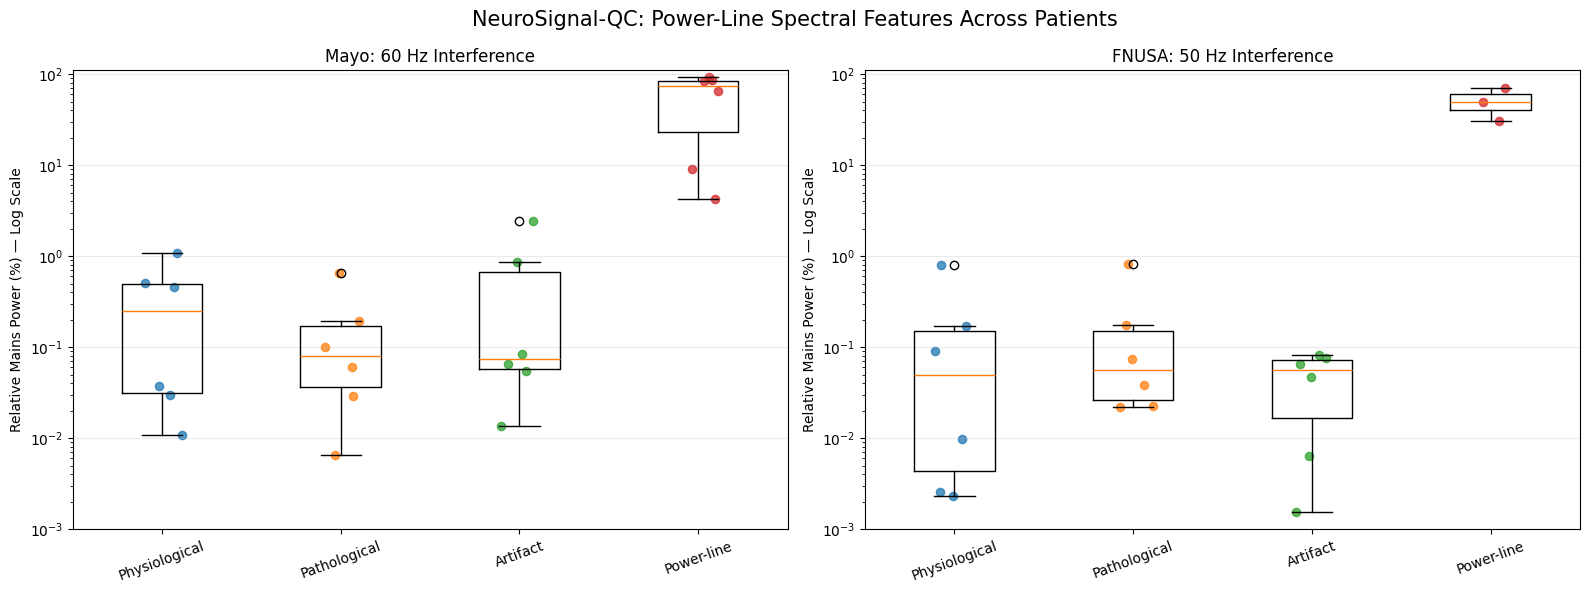


PILOT SPECTRAL ANALYSIS COMPLETE
Total EEG clips: 45
Unique participants: 32

No detection thresholds have been applied.
Results are exploratory and not clinical validation.


In [15]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 7
# Patient-Diverse Power-Line Spectral Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

HOSPITALS = ["Mayo", "FNUSA"]

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

MAINS_FREQUENCIES = {
    "Mayo": 60,
    "FNUSA": 50
}

spectral_pilot_records = []

print("=" * 70)
print("NEUROSIGNAL-QC — PATIENT-DIVERSE SPECTRAL ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 2. Retrieve the selected clips and their recording metadata
# ------------------------------------------------------------

for hospital in HOSPITALS:

    dataset_id = DATASETS[hospital]

    selected = patient_audit_df[
        patient_audit_df["Hospital"] == hospital
    ].copy()

    # Match selected clips to their original event metadata
    catalog = events[hospital][
        [
            "store_path",
            "sample_index",
            "subject",
            "label",
            "group_name"
        ]
    ].rename(
        columns={
            "store_path": "Store",
            "sample_index": "Sample Index",
            "subject": "Subject",
            "label": "Category"
        }
    )

    keys = [
        "Store",
        "Sample Index",
        "Subject",
        "Category"
    ]

    selected = selected.merge(
        catalog,
        on=keys,
        how="left",
        validate="one_to_one"
    )

    if selected["group_name"].isna().any():
        raise ValueError(
            f"Missing recording metadata for {hospital}"
        )

    print(f"\nHospital: {hospital}")
    print(f"Selected EEG clips: {len(selected)}")

    # --------------------------------------------------------
    # 3. Analyze each selected EEG clip
    # --------------------------------------------------------

    for _, row in selected.iterrows():

        store_path = row["Store"]
        group_name = row["group_name"]

        start = int(row["Sample Index"])

        # Reuse remote stores opened in Cell 6
        cache_key = (
            dataset_id,
            store_path
        )

        root = opened_stores[cache_key]

        group = root[group_name]

        signal_array = group["0"]

        fs = float(group.attrs["rate"])

        n_samples = int(round(3 * fs))

        # Retrieve signal
        digital = np.asarray(
            signal_array[
                0,
                start:start + n_samples
            ],
            dtype=np.float64
        )

        if len(digital) != n_samples:
            raise ValueError(
                "Incomplete EEG signal encountered."
            )

        scale = float(
            signal_array.attrs["scale"][0]
        )

        offset = float(
            signal_array.attrs["offset"][0]
        )

        eeg = digital * scale + offset

        if not np.all(np.isfinite(eeg)):
            raise ValueError(
                "Nonfinite EEG values encountered."
            )

        # ----------------------------------------------------
        # 4. Calculate Welch Power Spectral Density
        # ----------------------------------------------------

        frequencies, psd = welch(
            eeg,
            fs=fs,
            window="hann",
            nperseg=2048,
            noverlap=1024,
            detrend="constant",
            scaling="density"
        )

        # ----------------------------------------------------
        # 5. Calculate total spectral power (1–150 Hz)
        # ----------------------------------------------------

        total_mask = (
            (frequencies >= 1)
            & (frequencies <= 150)
        )

        total_power = np.trapezoid(
            psd[total_mask],
            frequencies[total_mask]
        )

        # ----------------------------------------------------
        # 6. Calculate relative mains-frequency power
        # ----------------------------------------------------

        mains = MAINS_FREQUENCIES[hospital]

        mains_mask = (
            (frequencies >= mains - 2)
            & (frequencies <= mains + 2)
        )

        mains_power = np.trapezoid(
            psd[mains_mask],
            frequencies[mains_mask]
        )

        relative_mains_power = (
            100 * mains_power / total_power
            if total_power > 0
            else np.nan
        )

        # ----------------------------------------------------
        # 7. Store results
        # ----------------------------------------------------

        spectral_pilot_records.append({
            "Hospital": hospital,
            "Subject": row["Subject"],
            "Category": row["Category"],
            "Mains Frequency (Hz)": mains,
            "Relative Mains Power (%)": relative_mains_power,
            "Total Power (1-150 Hz)": total_power
        })

# ============================================================
# 8. Create results dataframe
# ============================================================

spectral_pilot_df = pd.DataFrame(
    spectral_pilot_records
)

print("\n" + "=" * 70)
print("SPECTRAL ANALYSIS SUMMARY")
print("=" * 70)

summary = (
    spectral_pilot_df
    .groupby(
        ["Hospital", "Category"],
        observed=True
    )["Relative Mains Power (%)"]
    .agg(
        Clips="count",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

display(
    summary.round(4)
)

# ============================================================
# 9. Calculate interquartile ranges
# ============================================================

print("\n" + "=" * 70)
print("SPECTRAL POWER DISTRIBUTION — MEDIAN AND IQR")
print("=" * 70)

iqr_summary = (
    spectral_pilot_df
    .groupby(
        ["Hospital", "Category"],
        observed=True
    )["Relative Mains Power (%)"]
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Median="median",
        Q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

display(
    iqr_summary.round(4)
)

# ============================================================
# 10. Visualize spectral-power distributions
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

rng = np.random.default_rng(42)

for i, hospital in enumerate(HOSPITALS):

    ax = axes[i]

    hospital_df = spectral_pilot_df[
        spectral_pilot_df["Hospital"] == hospital
    ]

    plot_data = []

    for category in CATEGORIES:

        values = hospital_df[
            hospital_df["Category"] == category
        ]["Relative Mains Power (%)"].dropna().to_numpy()

        plot_data.append(values)

    # Boxplots show distribution summaries
    ax.boxplot(
        plot_data,
        tick_labels=CATEGORIES,
        showfliers=True
    )

    # Individual dots show every patient-selected clip
    for j, values in enumerate(plot_data, start=1):

        jitter = rng.uniform(
            -0.12,
            0.12,
            size=len(values)
        )

        ax.scatter(
            np.full(len(values), j) + jitter,
            np.maximum(values, 0.001),
            alpha=0.75,
            s=35
        )

    ax.set_yscale("log")

    ax.set_ylim(0.001, 110)

    ax.set_title(
        f"{hospital}: {MAINS_FREQUENCIES[hospital]} Hz Interference"
    )

    ax.set_ylabel(
        "Relative Mains Power (%) — Log Scale"
    )

    ax.tick_params(
        axis="x",
        rotation=20
    )

    ax.grid(
        alpha=0.25,
        axis="y"
    )

plt.suptitle(
    "NeuroSignal-QC: Power-Line Spectral Features Across Patients",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ============================================================
# 11. Final summary
# ============================================================

print("\n" + "=" * 70)
print("PILOT SPECTRAL ANALYSIS COMPLETE")
print("=" * 70)

print(
    "Total EEG clips:",
    len(spectral_pilot_df)
)

print(
    "Unique participants:",
    spectral_pilot_df[
        ["Hospital", "Subject"]
    ].drop_duplicates().shape[0]
)

print("\nNo detection thresholds have been applied.")
print("Results are exploratory and not clinical validation.")

### Expanded Spectral Feature Investigation

We expand the analysis beyond individual examples
to investigate overlap between annotation categories.

Recordings are selected with limits on the number
of clips contributed by each participant.

The expanded sample is exploratory and should
not be interpreted as an independent validation set.

NEUROSIGNAL-QC — EXPANDED SPECTRAL ANALYSIS

Hospital: Mayo
  Physiological: 30 clips | 13 participants
  Pathological: 30 clips | 6 participants
  Artifact: 30 clips | 14 participants
  Power-line: 30 clips | 8 participants

Hospital: FNUSA
  Physiological: 30 clips | 9 participants
  Pathological: 30 clips | 12 participants
  Artifact: 30 clips | 10 participants
  Power-line: 15 clips | 3 participants

EXPANDED SPECTRAL ANALYSIS SUMMARY


,Hospital,Category,Clips,Unique_Subjects,Median_Mains_Power,Minimum_Mains_Power,Maximum_Mains_Power,Max_Flatline_s
0,FNUSA,Artifact,30,10,0.0650,0.0017,2.0979,0.002
1,FNUSA,Pathological,30,12,0.1036,0.0079,2.3409,0.003
2,FNUSA,Physiological,30,9,0.0508,0.0032,1.2018,0.002
3,FNUSA,Power-line,15,3,50.9039,19.7534,78.7303,0.002
4,Mayo,Artifact,30,14,0.1757,0.0103,4.6254,0.002
5,Mayo,Pathological,30,6,0.0589,0.0077,1.0271,0.003
6,Mayo,Physiological,30,13,0.1174,0.0067,2.1789,0.003
7,Mayo,Power-line,30,8,30.9325,0.0652,96.9198,0.002


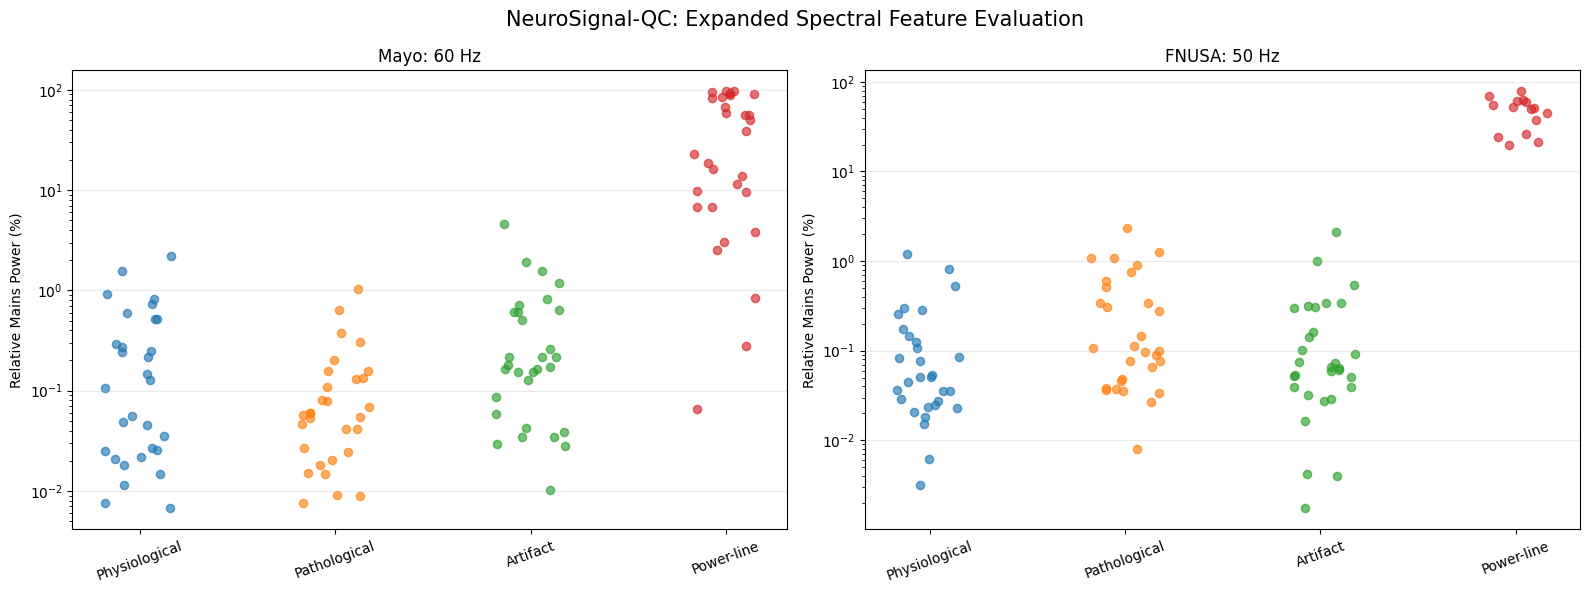


EXPANDED ANALYSIS COMPLETE
Additional EEG clips analyzed: 225
Unique participants: 38
Overlap with previous pilot clips: 0

No classification thresholds applied.
Expanded analysis complete.


In [16]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 8
# Expanded Spectral Analysis Across EEG Recordings
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import zarr
from zarr.storage import FsspecStore
from scipy.signal import welch
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)

HOSPITALS = ["Mayo", "FNUSA"]

CATEGORIES = [
    "Physiological",
    "Pathological",
    "Artifact",
    "Power-line"
]

MAINS_FREQUENCIES = {
    "Mayo": 60,
    "FNUSA": 50
}

TARGET_CLIPS_PER_CATEGORY = 30
MAX_CLIPS_PER_SUBJECT = 5

expanded_records = []

# ------------------------------------------------------------
# 2. Exclude the recordings used in our previous pilot
# ------------------------------------------------------------

pilot_keys = set(
    zip(
        patient_audit_df["Hospital"].astype(str),
        patient_audit_df["Store"].astype(str),
        patient_audit_df["Sample Index"].astype(int)
    )
)

print("=" * 70)
print("NEUROSIGNAL-QC — EXPANDED SPECTRAL ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 3. Select additional recordings
# ------------------------------------------------------------

for hospital in HOSPITALS:

    dataset_id = DATASETS[hospital]

    print(f"\nHospital: {hospital}")

    for category in CATEGORIES:

        pool = events[hospital][
            events[hospital]["label"] == category
        ].copy()

        pool = pool.dropna(
            subset=[
                "subject",
                "store_path",
                "group_name",
                "sample_index",
                "duration_s"
            ]
        )

        pool["sample_index"] = pd.to_numeric(
            pool["sample_index"],
            errors="coerce"
        )

        pool = pool[
            pool["sample_index"].notna()
            & (pool["sample_index"] >= 0)
            & (pool["duration_s"] > 0)
        ].copy()

        pool["sample_index"] = (
            pool["sample_index"].astype(int)
        )

        pool["subject"] = (
            pool["subject"].astype(str)
        )

        pool = pool.drop_duplicates(
            subset=[
                "store_path",
                "group_name",
                "sample_index"
            ]
        )

        # Remove previously analyzed pilot clips
        new_clip_mask = [
            (
                hospital,
                str(store),
                int(start)
            ) not in pilot_keys

            for store, start in zip(
                pool["store_path"],
                pool["sample_index"]
            )
        ]

        pool = pool.loc[new_clip_mask].copy()

        # ----------------------------------------------------
        # 4. Prepare a balanced participant selection
        # ----------------------------------------------------

        subject_queues = {}

        for subject, group_df in pool.groupby(
            "subject",
            observed=True
        ):

            shuffled_indices = rng.permutation(
                group_df.index.to_numpy()
            )

            subject_queues[subject] = list(
                shuffled_indices[
                    :MAX_CLIPS_PER_SUBJECT
                ]
            )

        chosen_indices = []

        # Round-robin sampling across participants
        while len(chosen_indices) < TARGET_CLIPS_PER_CATEGORY:

            available_subjects = [
                subject
                for subject, queue in subject_queues.items()
                if len(queue) > 0
            ]

            if not available_subjects:
                break

            for subject in rng.permutation(
                available_subjects
            ):

                chosen_indices.append(
                    subject_queues[subject].pop()
                )

                if (
                    len(chosen_indices)
                    >= TARGET_CLIPS_PER_CATEGORY
                ):
                    break

        selected = pool.loc[
            chosen_indices
        ].copy()

        print(
            f"  {category}: "
            f"{len(selected)} clips | "
            f"{selected['subject'].nunique()} participants"
        )

        # ----------------------------------------------------
        # 5. Retrieve recordings and calculate spectral power
        # ----------------------------------------------------

        for _, row in selected.iterrows():

            store_path = row["store_path"]
            group_name = row["group_name"]

            start = int(row["sample_index"])

            cache_key = (
                dataset_id,
                store_path
            )

            if cache_key not in opened_stores:

                s3_uri = (
                    f"s3://nemar/{dataset_id}/zarr/"
                    f"{store_path}"
                )

                remote_store = FsspecStore.from_url(
                    s3_uri,
                    storage_options={
                        "anon": True,
                        "client_kwargs": {
                            "region_name": "us-east-2"
                        }
                    }
                )

                opened_stores[cache_key] = (
                    zarr.open_group(
                        store=remote_store,
                        mode="r",
                        zarr_format=3
                    )
                )

            root = opened_stores[cache_key]

            group = root[group_name]

            signal_array = group["0"]

            fs = float(group.attrs["rate"])

            n_samples = int(
                round(float(row["duration_s"]) * fs)
            )

            digital = np.asarray(
                signal_array[
                    0,
                    start:start + n_samples
                ],
                dtype=np.float64
            )

            if len(digital) != n_samples:
                raise ValueError(
                    f"Incomplete recording: "
                    f"{hospital}, {row['subject']}"
                )

            scale = float(
                signal_array.attrs["scale"][0]
            )

            offset = float(
                signal_array.attrs["offset"][0]
            )

            eeg = digital * scale + offset

            if not np.all(np.isfinite(eeg)):
                raise ValueError(
                    "Nonfinite signal values detected."
                )

            # ------------------------------------------------
            # 6. Welch Power Spectral Density
            # ------------------------------------------------

            frequencies, psd = welch(
                eeg,
                fs=fs,
                window="hann",
                nperseg=2048,
                noverlap=1024,
                detrend="constant",
                scaling="density"
            )

            total_mask = (
                (frequencies >= 1)
                & (frequencies <= 150)
            )

            total_power = np.trapezoid(
                psd[total_mask],
                frequencies[total_mask]
            )

            mains = MAINS_FREQUENCIES[hospital]

            mains_mask = (
                (frequencies >= mains - 2)
                & (frequencies <= mains + 2)
            )

            mains_power = np.trapezoid(
                psd[mains_mask],
                frequencies[mains_mask]
            )

            relative_mains_power = (
                100 * mains_power / total_power
                if total_power > 0
                else np.nan
            )

            # ------------------------------------------------
            # 7. Measure flatline duration
            # ------------------------------------------------

            changes = np.flatnonzero(
                np.r_[
                    True,
                    eeg[1:] != eeg[:-1]
                ]
            )

            run_lengths = np.diff(
                np.r_[changes, len(eeg)]
            )

            longest_flatline = (
                np.max(run_lengths) / fs
            )

            # ------------------------------------------------
            # 8. Store results
            # ------------------------------------------------

            expanded_records.append({
                "Hospital": hospital,
                "Subject": row["subject"],
                "Category": category,
                "Store": store_path,
                "Sample Index": start,
                "Relative Mains Power (%)":
                    relative_mains_power,
                "Total Spectral Power": total_power,
                "Longest Flatline (s)": longest_flatline
            })

# ============================================================
# 9. Results dataframe
# ============================================================

expanded_spectral_df = pd.DataFrame(
    expanded_records
)

print("\n" + "=" * 70)
print("EXPANDED SPECTRAL ANALYSIS SUMMARY")
print("=" * 70)

expanded_summary = (
    expanded_spectral_df
    .groupby(
        ["Hospital", "Category"],
        observed=True
    )
    .agg(
        Clips=("Subject", "count"),
        Unique_Subjects=("Subject", "nunique"),
        Median_Mains_Power=(
            "Relative Mains Power (%)",
            "median"
        ),
        Minimum_Mains_Power=(
            "Relative Mains Power (%)",
            "min"
        ),
        Maximum_Mains_Power=(
            "Relative Mains Power (%)",
            "max"
        ),
        Max_Flatline_s=(
            "Longest Flatline (s)",
            "max"
        )
    )
    .reset_index()
)

display(expanded_summary.round(4))

# ============================================================
# 10. Visualize spectral separation
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for i, hospital in enumerate(HOSPITALS):

    ax = axes[i]

    hospital_df = expanded_spectral_df[
        expanded_spectral_df["Hospital"] == hospital
    ]

    for j, category in enumerate(CATEGORIES):

        values = hospital_df[
            hospital_df["Category"] == category
        ]["Relative Mains Power (%)"].dropna().to_numpy()

        jitter = rng.uniform(
            -0.18,
            0.18,
            size=len(values)
        )

        ax.scatter(
            np.full(len(values), j) + jitter,
            np.maximum(values, 0.0001),
            alpha=0.65,
            s=35,
            label=category
        )

    ax.set_yscale("log")

    ax.set_xticks(range(4))
    ax.set_xticklabels(
        CATEGORIES,
        rotation=20
    )

    ax.set_title(
        f"{hospital}: {MAINS_FREQUENCIES[hospital]} Hz"
    )

    ax.set_ylabel(
        "Relative Mains Power (%)"
    )

    ax.grid(
        alpha=0.25,
        axis="y"
    )

plt.suptitle(
    "NeuroSignal-QC: Expanded Spectral Feature Evaluation",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ============================================================
# 11. Verify no pilot recordings were reused
# ============================================================

expanded_keys = set(
    zip(
        expanded_spectral_df["Hospital"],
        expanded_spectral_df["Store"],
        expanded_spectral_df["Sample Index"]
    )
)

overlap = len(
    pilot_keys.intersection(expanded_keys)
)

print("\n" + "=" * 70)
print("EXPANDED ANALYSIS COMPLETE")
print("=" * 70)

print(
    "Additional EEG clips analyzed:",
    len(expanded_spectral_df)
)

print(
    "Unique participants:",
    expanded_spectral_df[
        ["Hospital", "Subject"]
    ].drop_duplicates().shape[0]
)

print(
    "Overlap with previous pilot clips:",
    overlap
)

assert overlap == 0, \
    "Previously analyzed clips were reused."

print("\nNo classification thresholds applied.")
print("Expanded analysis complete.")

MAYO — SPECTRAL OVERLAP INVESTIGATION

Lowest power-line mains power: 0.0652%
Highest non-power-line mains power: 4.6254%

Power-line recordings overlapping the non-power-line feature range: 6 / 30

Overlapping power-line recordings:


,Subject,Category,Sample Index,Relative Mains Power (%)
92,016,Power-line,54000,0.06519
111,012,Power-line,1467000,0.27693
117,012,Power-line,729000,0.83381
119,022,Power-line,4470000,2.50343
94,013,Power-line,807000,3.05772
103,016,Power-line,27000,3.78257



RECORDINGS SELECTED FOR INVESTIGATION


,Subject,Category,Sample Index,Relative Mains Power (%)
0,016,Power-line,54000,0.06519
1,012,Power-line,1467000,0.27693
2,012,Power-line,729000,0.83381
3,000,Artifact,420000,4.62537
4,000,Physiological,1056000,2.17891


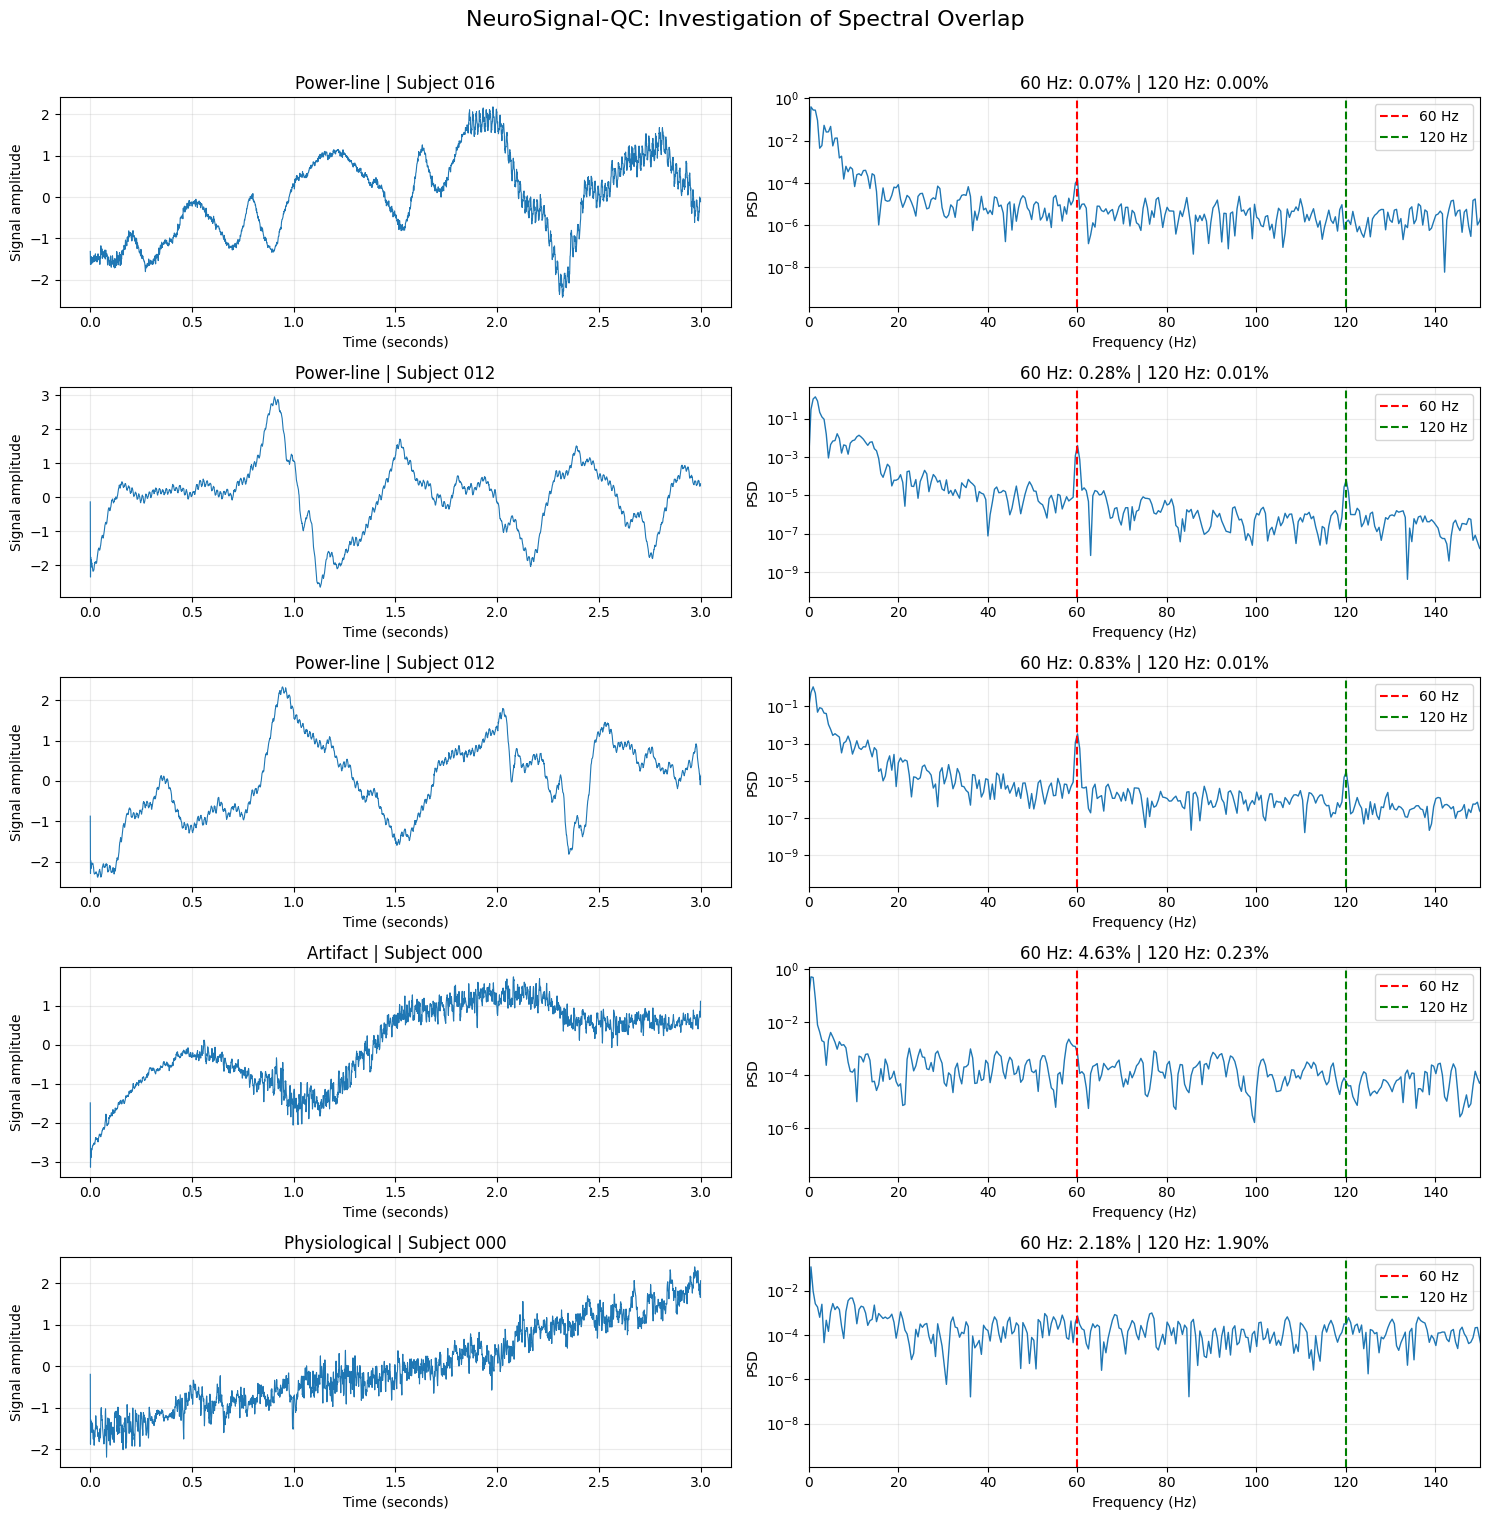


POWER-LINE HARMONIC ANALYSIS


,Subject,Category,Sample Index,60 Hz Power (%),120 Hz Power (%),Combined Power (%)
0,016,Power-line,54000,0.06519,0.00494,0.07013
1,012,Power-line,1467000,0.27693,0.00502,0.28195
2,012,Power-line,729000,0.83381,0.00854,0.84235
3,000,Artifact,420000,4.62537,0.23214,4.85751
4,000,Physiological,1056000,2.17891,1.90145,4.08036



Spectral overlap investigation complete.
No detection thresholds or classifiers were applied.


In [17]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 9
# Spectral Overlap and Power-Line Harmonic Investigation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from IPython.display import display

# ------------------------------------------------------------
# 1. Identify overlapping spectral measurements
# ------------------------------------------------------------

mayo_df = expanded_spectral_df[
    expanded_spectral_df["Hospital"] == "Mayo"
].copy()

powerline_df = mayo_df[
    mayo_df["Category"] == "Power-line"
].copy()

non_powerline_df = mayo_df[
    mayo_df["Category"] != "Power-line"
].copy()

feature = "Relative Mains Power (%)"

max_non_powerline = non_powerline_df[feature].max()

min_powerline = powerline_df[feature].min()

overlapping_powerline = powerline_df[
    powerline_df[feature] <= max_non_powerline
]

print("=" * 70)
print("MAYO — SPECTRAL OVERLAP INVESTIGATION")
print("=" * 70)

print(
    f"\nLowest power-line mains power: "
    f"{min_powerline:.4f}%"
)

print(
    f"Highest non-power-line mains power: "
    f"{max_non_powerline:.4f}%"
)

print(
    f"\nPower-line recordings overlapping the "
    f"non-power-line feature range: "
    f"{len(overlapping_powerline)} / {len(powerline_df)}"
)

print("\nOverlapping power-line recordings:")

display(
    overlapping_powerline[
        [
            "Subject",
            "Category",
            "Sample Index",
            feature
        ]
    ].sort_values(feature).round(5)
)

# ------------------------------------------------------------
# 2. Select recordings for detailed inspection
# ------------------------------------------------------------

lowest_powerline = powerline_df.nsmallest(
    3,
    feature
)

highest_non_powerline = non_powerline_df.nlargest(
    2,
    feature
)

focus_df = pd.concat(
    [
        lowest_powerline,
        highest_non_powerline
    ],
    ignore_index=True
)

print("\n" + "=" * 70)
print("RECORDINGS SELECTED FOR INVESTIGATION")
print("=" * 70)

display(
    focus_df[
        [
            "Subject",
            "Category",
            "Sample Index",
            feature
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 3. Retrieve waveforms and calculate spectral features
# ------------------------------------------------------------

harmonic_records = []

fig, axes = plt.subplots(
    len(focus_df),
    2,
    figsize=(15, 3 * len(focus_df))
)

for i, (_, row) in enumerate(focus_df.iterrows()):

    store_path = row["Store"]

    start = int(row["Sample Index"])

    # Retrieve the recording's signal group
    matching_events = events["Mayo"][
        (events["Mayo"]["store_path"] == store_path)
        &
        (events["Mayo"]["sample_index"] == start)
    ]

    if matching_events.empty:
        raise ValueError(
            "Could not locate recording metadata."
        )

    group_name = matching_events.iloc[0]["group_name"]

    # Reuse the remote recording cache
    cache_key = (
        DATASETS["Mayo"],
        store_path
    )

    root = opened_stores[cache_key]

    group = root[group_name]

    signal_array = group["0"]

    fs = float(group.attrs["rate"])

    n_samples = int(round(3 * fs))

    # Retrieve the EEG segment
    digital = np.asarray(
        signal_array[
            0,
            start:start + n_samples
        ],
        dtype=np.float64
    )

    if len(digital) != n_samples:
        raise ValueError("Incomplete EEG segment.")

    scale = float(signal_array.attrs["scale"][0])
    offset = float(signal_array.attrs["offset"][0])

    eeg = digital * scale + offset

    if not np.all(np.isfinite(eeg)):
        raise ValueError("Nonfinite EEG samples detected.")

    time = np.arange(len(eeg)) / fs

    # --------------------------------------------------------
    # 4. Calculate Welch Power Spectral Density
    # --------------------------------------------------------

    frequencies, psd = welch(
        eeg,
        fs=fs,
        window="hann",
        nperseg=2048,
        noverlap=1024,
        detrend="constant",
        scaling="density"
    )

    total_mask = (
        (frequencies >= 1)
        & (frequencies <= 150)
    )

    total_power = np.trapezoid(
        psd[total_mask],
        frequencies[total_mask]
    )

    if total_power <= 0:
        raise ValueError(
            "Cannot calculate relative spectral power."
        )

    # --------------------------------------------------------
    # 5. Calculate power around 60 Hz and 120 Hz
    # --------------------------------------------------------

    fundamental_mask = (
        (frequencies >= 58)
        & (frequencies <= 62)
    )

    harmonic_mask = (
        (frequencies >= 118)
        & (frequencies <= 122)
    )

    fundamental_power = np.trapezoid(
        psd[fundamental_mask],
        frequencies[fundamental_mask]
    )

    harmonic_power = np.trapezoid(
        psd[harmonic_mask],
        frequencies[harmonic_mask]
    )

    relative_60 = (
        100 * fundamental_power / total_power
    )

    relative_120 = (
        100 * harmonic_power / total_power
    )

    combined_power = (
        relative_60 + relative_120
    )

    harmonic_records.append({
        "Subject": row["Subject"],
        "Category": row["Category"],
        "Sample Index": start,
        "60 Hz Power (%)": relative_60,
        "120 Hz Power (%)": relative_120,
        "Combined Power (%)": combined_power
    })

    # --------------------------------------------------------
    # 6. Plot time-domain EEG
    # --------------------------------------------------------

    ax_time = axes[i, 0]

    ax_time.plot(
        time,
        eeg,
        linewidth=0.8
    )

    ax_time.set_title(
        f"{row['Category']} | Subject {row['Subject']}"
    )

    ax_time.set_xlabel("Time (seconds)")

    ax_time.set_ylabel("Signal amplitude")

    ax_time.grid(alpha=0.25)

    # --------------------------------------------------------
    # 7. Plot frequency-domain EEG
    # --------------------------------------------------------

    ax_psd = axes[i, 1]

    ax_psd.semilogy(
        frequencies,
        np.maximum(psd, 1e-15),
        linewidth=1
    )

    ax_psd.axvline(
        60,
        color="red",
        linestyle="--",
        label="60 Hz"
    )

    ax_psd.axvline(
        120,
        color="green",
        linestyle="--",
        label="120 Hz"
    )

    ax_psd.set_xlim(0, 150)

    ax_psd.set_xlabel("Frequency (Hz)")

    ax_psd.set_ylabel("PSD")

    ax_psd.set_title(
        f"60 Hz: {relative_60:.2f}% | "
        f"120 Hz: {relative_120:.2f}%"
    )

    ax_psd.legend()

    ax_psd.grid(alpha=0.25)

plt.suptitle(
    "NeuroSignal-QC: Investigation of Spectral Overlap",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# 8. Display harmonic analysis results
# ============================================================

harmonic_df = pd.DataFrame(harmonic_records)

print("\n" + "=" * 70)
print("POWER-LINE HARMONIC ANALYSIS")
print("=" * 70)

display(
    harmonic_df.round(5)
)

print("\nSpectral overlap investigation complete.")
print("No detection thresholds or classifiers were applied.")

NEUROSIGNAL-QC — LOCAL SPECTRAL PROMINENCE


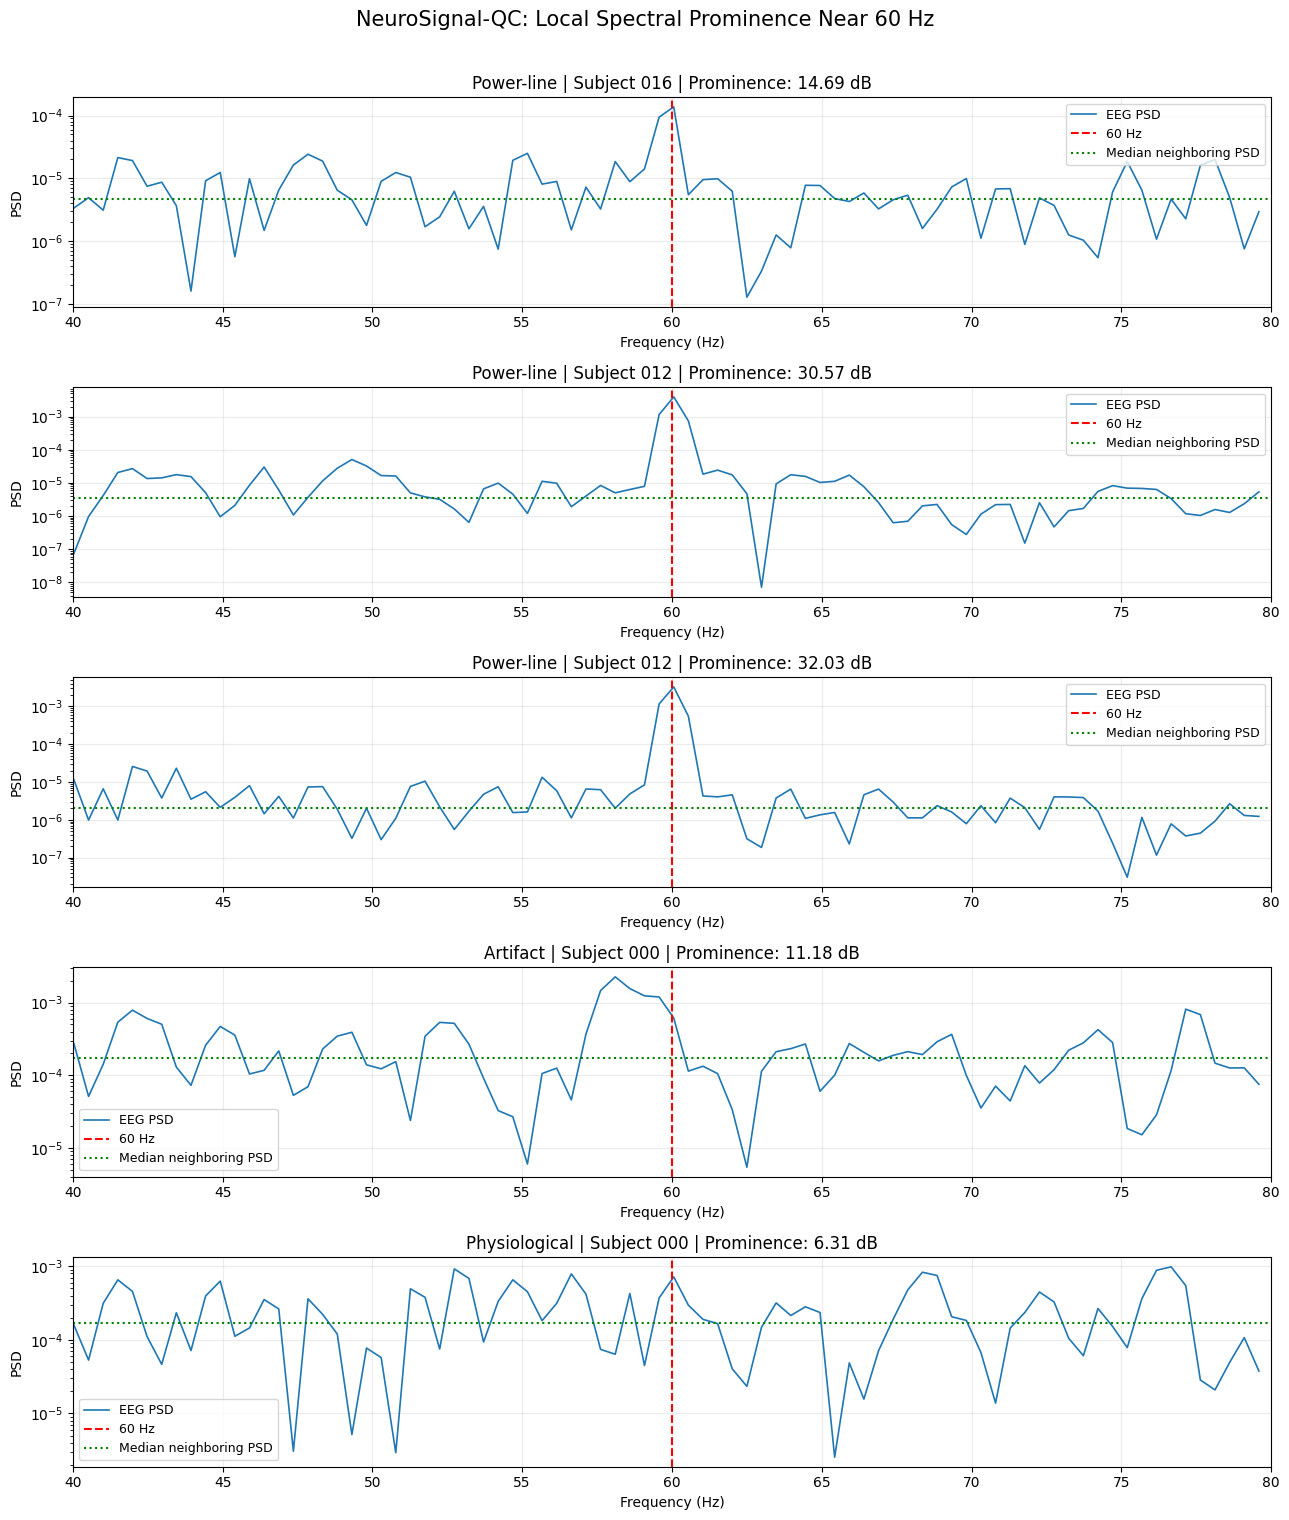


LOCAL SPECTRAL PROMINENCE RESULTS


,Subject,Category,Sample Index,Relative 60 Hz Power (%),Detected Peak (Hz),Local Prominence (dB)
0,016,Power-line,54000,0.0652,60.0586,14.6892
1,012,Power-line,1467000,0.2769,60.0586,30.5654
2,012,Power-line,729000,0.8338,60.0586,32.0281
3,000,Artifact,420000,4.6254,58.1055,11.1789
4,000,Physiological,1056000,2.1789,60.0586,6.3100



FEATURE COMPARISON


,Subject,Category,Relative 60 Hz Power (%),Local Prominence (dB)
0,016,Power-line,0.0652,14.6892
1,012,Power-line,0.2769,30.5654
2,012,Power-line,0.8338,32.0281
3,000,Artifact,4.6254,11.1789
4,000,Physiological,2.1789,6.3100



Local spectral prominence investigation complete.
No detection thresholds or classifiers applied.


In [18]:
# ============================================================
# NEUROSIGNAL-QC
# PHASE 2 — CELL 10
# Local Spectral Prominence Investigation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MAINS_FREQUENCY = 60

PEAK_RANGE = (58, 62)

BACKGROUND_RANGES = [
    (45, 55),
    (65, 75)
]

prominence_records = []

fig, axes = plt.subplots(
    len(focus_df),
    1,
    figsize=(13, 3 * len(focus_df))
)

axes = np.atleast_1d(axes)

print("=" * 70)
print("NEUROSIGNAL-QC — LOCAL SPECTRAL PROMINENCE")
print("=" * 70)

# ------------------------------------------------------------
# 2. Analyze the five previously selected recordings
# ------------------------------------------------------------

for i, (_, row) in enumerate(focus_df.iterrows()):

    store_path = row["Store"]
    start = int(row["Sample Index"])

    # Locate the EEG signal group
    matching_events = events["Mayo"][
        (events["Mayo"]["store_path"] == store_path)
        &
        (events["Mayo"]["sample_index"] == start)
    ]

    if matching_events.empty:
        raise ValueError("Recording metadata not found.")

    group_name = matching_events.iloc[0]["group_name"]

    # Reuse previously opened recording stores
    cache_key = (
        DATASETS["Mayo"],
        store_path
    )

    root = opened_stores[cache_key]

    group = root[group_name]

    signal_array = group["0"]

    fs = float(group.attrs["rate"])

    n_samples = int(round(3 * fs))

    # --------------------------------------------------------
    # 3. Retrieve the EEG signal
    # --------------------------------------------------------

    digital = np.asarray(
        signal_array[
            0,
            start:start + n_samples
        ],
        dtype=np.float64
    )

    if len(digital) != n_samples:
        raise ValueError("Incomplete EEG recording.")

    scale = float(signal_array.attrs["scale"][0])
    offset = float(signal_array.attrs["offset"][0])

    eeg = digital * scale + offset

    if not np.all(np.isfinite(eeg)):
        raise ValueError("Nonfinite EEG samples detected.")

    # --------------------------------------------------------
    # 4. Calculate Welch Power Spectral Density
    # --------------------------------------------------------

    frequencies, psd = welch(
        eeg,
        fs=fs,
        window="hann",
        nperseg=2048,
        noverlap=1024,
        detrend="constant",
        scaling="density"
    )

    # --------------------------------------------------------
    # 5. Identify local mains-frequency peak
    # --------------------------------------------------------

    peak_mask = (
        (frequencies >= PEAK_RANGE[0])
        &
        (frequencies <= PEAK_RANGE[1])
    )

    peak_psd_values = psd[peak_mask]

    peak_frequencies = frequencies[peak_mask]

    peak_index = np.argmax(peak_psd_values)

    peak_power = float(
        peak_psd_values[peak_index]
    )

    detected_peak_frequency = float(
        peak_frequencies[peak_index]
    )

    # --------------------------------------------------------
    # 6. Estimate neighboring spectral background
    # --------------------------------------------------------

    background_mask = (
        (
            (frequencies >= BACKGROUND_RANGES[0][0])
            &
            (frequencies <= BACKGROUND_RANGES[0][1])
        )
        |
        (
            (frequencies >= BACKGROUND_RANGES[1][0])
            &
            (frequencies <= BACKGROUND_RANGES[1][1])
        )
    )

    background_values = psd[background_mask]

    background_power = float(
        np.median(background_values)
    )

    # --------------------------------------------------------
    # 7. Calculate local spectral prominence
    # --------------------------------------------------------

    if background_power <= 0:
        prominence_db = np.nan
    else:
        prominence_db = (
            10 * np.log10(
                peak_power / background_power
            )
        )

    # --------------------------------------------------------
    # 8. Store results
    # --------------------------------------------------------

    prominence_records.append({
        "Subject": row["Subject"],
        "Category": row["Category"],
        "Sample Index": start,
        "Relative 60 Hz Power (%)":
            row["Relative Mains Power (%)"],
        "Detected Peak (Hz)":
            detected_peak_frequency,
        "Local Prominence (dB)":
            prominence_db
    })

    # --------------------------------------------------------
    # 9. Visualize local frequency spectrum
    # --------------------------------------------------------

    ax = axes[i]

    local_mask = (
        (frequencies >= 40)
        &
        (frequencies <= 80)
    )

    ax.semilogy(
        frequencies[local_mask],
        psd[local_mask],
        linewidth=1.2,
        label="EEG PSD"
    )

    ax.axvline(
        MAINS_FREQUENCY,
        color="red",
        linestyle="--",
        label="60 Hz"
    )

    ax.axhline(
        max(background_power, np.finfo(float).tiny),
        color="green",
        linestyle=":",
        label="Median neighboring PSD"
    )

    ax.set_xlim(40, 80)

    ax.set_title(
        f"{row['Category']} | "
        f"Subject {row['Subject']} | "
        f"Prominence: {prominence_db:.2f} dB"
    )

    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD")

    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)

plt.suptitle(
    "NeuroSignal-QC: Local Spectral Prominence Near 60 Hz",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# 10. Results table
# ============================================================

prominence_df = pd.DataFrame(
    prominence_records
)

print("\n" + "=" * 70)
print("LOCAL SPECTRAL PROMINENCE RESULTS")
print("=" * 70)

display(prominence_df.round(4))

# ------------------------------------------------------------
# 11. Compare the two measurements
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE COMPARISON")
print("=" * 70)

comparison = prominence_df[
    [
        "Subject",
        "Category",
        "Relative 60 Hz Power (%)",
        "Local Prominence (dB)"
    ]
].copy()

display(comparison.round(4))

print("\nLocal spectral prominence investigation complete.")
print("No detection thresholds or classifiers applied.")